# Fase 3 — Entrenamiento y versionado del modelo

El objetivo es estimar el cierre de frío del día calendario siguiente. Cada fila conserva la fecha de emisión **D** y `y` representa el cierre de **D+1**.

- **Train** ajusta los modelos y la escala de Ridge.
- **Validation** compara alternativas y elige por MAE.
- **Test** se evalúa luego de congelar la elección y reentrenar con Train y Validation.

Usamos los CSV y las huellas de la Fase 2. El script y la notebook comparten las mismas funciones.

In [1]:
import sys  
from datetime import datetime, timezone  
from pathlib import Path  
from tempfile import TemporaryDirectory  

import matplotlib.pyplot as plt  
import pandas as pd  
from IPython.display import display  
from sklearn.inspection import permutation_importance  

raiz = Path.cwd()  
if raiz.name == "notebooks":  
    raiz = raiz.parent  
if str(raiz) not in sys.path:  
    sys.path.insert(0, str(raiz))  

# Importamos las mismas funciones que usa la ejecución por terminal.
from src.train_model import (BUSQUEDA, SEMILLA, comparar_modelos, crear_modelo,
                             leer_csv_verificado, leer_json, medir, registrar)

print("Semilla de los estimadores:", SEMILLA)  # Deja visible el control de aleatoriedad.

Semilla de los estimadores: 42


## 3.1 · Baselines y modelos

**Persistencia** predice que mañana se consumirá lo mismo que hoy. La **media móvil de siete días** suaviza variaciones de un día particular. Usa la ventana calendario que termina en D y la regla de cobertura de la Fase 2, con un mínimo de cuatro cierres válidos. El script comprueba que ambas referencias tengan un pronóstico para cada fecha evaluada.

| Modelo | Qué aprende | Qué ajustamos |
|---|---|---|
| Ridge | Una combinación lineal de las predictoras. La penalización L2 reduce coeficientes grandes, algo útil para variables relacionadas como las medias móviles. | Intensidad de regularización `alpha`. La escala se ajusta dentro del pipeline. |
| Random Forest | Promedia árboles entrenados con distintas muestras. Captura relaciones no lineales e interacciones. | Profundidad, tamaño mínimo de hoja y criterio de error. |
| XGBoost | Suma árboles pequeños en secuencia. Cada árbol ayuda a corregir el error de los anteriores. | Cantidad y profundidad de árboles, tasa de aprendizaje y función de pérdida. |
| LightGBM | También agrega árboles en secuencia y agrupa valores de las variables en histogramas. | Cantidad de árboles, hojas, tasa de aprendizaje, mínimo de observaciones y pérdida. |

Comparamos las 12 columnas de Fase 2 con tres variantes. Dos cambian las medias móviles y otra quita el ratio Frío/Servicios y Trafo 12. La media del baseline se sigue calculando en todas. El clima histórico permanece como diagnóstico hasta verificar que los valores puedan obtenerse al momento de pronosticar.

### Los dos baselines, antes del entrenamiento

La persistencia usa el cierre de D. Para la media móvil tomamos los siete días calendario que terminan en D, con el mínimo de cuatro cierres válidos fijado en Fase 2. Usamos la base diaria para que el baseline siga existiendo aunque la media de siete días se quite de las predictoras.

In [2]:
checksums = leer_json(raiz / "data" / "checksums.json")  
train = leer_csv_verificado("train.csv", checksums)  
val = leer_csv_verificado("validation.csv", checksums)  
diario = leer_csv_verificado("dataset_diario_base.csv", checksums)  # Incluye los cierres sin y.

# Usamos exactamente las filas de Validation y el orden de columnas de Fase 2.
columnas_fase2 = train.columns.drop("y").tolist()  
X_train = train[columnas_fase2]  # Mediciones conocidas al cierre de D.
y_train = train["y"]  
X_val = val[columnas_fase2]  # Mismas columnas en el tramo siguiente.
y_val = val["y"] 

# Reindexamos los cierres sobre el calendario, tal como hicimos en preprocesamiento.
columna_frio = "Frio (Kw)_Consolidado EE"  
frio = diario.loc[:val.index.max(), columna_frio].asfreq("D")  # Limita el historial al último D evaluado.
persistencia = frio.loc[val.index]  # Para D+1 se pronostica el cierre de D.
media_siete_dias = frio.rolling(7, min_periods=4).mean().loc[val.index]  # Ventana [D−6, D].
assert persistencia.notna().all() and media_siete_dias.notna().all()  

predicciones_baseline = {"Persistencia": persistencia, "Media móvil de 7 días": media_siete_dias}  
filas_baseline = []  
for nombre, prediccion in predicciones_baseline.items():  # Recorre los dos pronósticos simples.
    metricas_baseline = medir(y_val, prediccion) 
    filas_baseline.append({"modelo": nombre, **metricas_baseline}) 
display(pd.DataFrame(filas_baseline).round(2)) 

,modelo,mae,rmse,r2
0,Persistencia,2727.13,3362.14,0.22
1,Media móvil de 7 días,2395.32,3145.88,0.31


### Primer ajuste de cada familia

Ajustamos una configuración inicial de cada modelo sobre las 12 predictoras que quedaron en 2.3. Usamos la primera configuración de cada familia de la grilla. `fit` aprende con Train y `predict` produce el pronóstico para Validation. Esta prueba sirve para entender el recorrido de una corrida. En 3.2 repetimos el procedimiento con toda la grilla y las cuatro listas de predictoras.

In [3]:
filas_iniciales = []  # Guarda las métricas de las cuatro configuraciones iniciales.
fecha_corrida = datetime.now(timezone.utc).isoformat()  # Identifica la ejecución del ejemplo.

with TemporaryDirectory(prefix="tpf-primera-comparacion-") as carpeta:  # Aísla el registro del ejemplo.
    ruta_log_inicial = Path(carpeta) / "experimentos_3_1.csv"  
    for fila in filas_baseline:  
        metricas_baseline = {clave: fila[clave] for clave in ["mae", "rmse", "r2"]}  
        registrar(ruta_log_inicial, "baseline", fila["modelo"], "", {}, "validation", 0,
                  val.index, metricas_baseline, fecha_corrida)  

    for nombre, configuraciones in BUSQUEDA.items():  # Recorre Ridge, Random Forest, XGBoost y LightGBM.
        parametros = configuraciones[0]  
        modelo = crear_modelo(nombre, parametros)  # Construye el modelo con la semilla fijada.
        modelo.fit(X_train, y_train)  # Aprende solo con Train.
        prediccion = modelo.predict(X_val) 
        metricas_modelo = medir(y_val, prediccion) 
        registrar(ruta_log_inicial, "candidato", nombre, "Fase 2 completa", parametros, "validation",
                  len(train), val.index, metricas_modelo, fecha_corrida) 
        filas_iniciales.append({"modelo": nombre, **metricas_modelo})  
    assert len(pd.read_csv(ruta_log_inicial)) == 6  

tabla_inicial = pd.DataFrame(filas_baseline + filas_iniciales)  # Junta las seis filas de 3.1.
display(tabla_inicial.sort_values("mae").round(2))  

,modelo,mae,rmse,r2
2,Ridge,2159.67,2786.04,0.46
4,XGBoost,2372.06,2991.99,0.38
3,Random Forest,2374.79,2918.35,0.41
1,Media móvil de 7 días,2395.32,3145.88,0.31
5,LightGBM,2404.29,2965.39,0.39
0,Persistencia,2727.13,3362.14,0.22


## 3.2 · Espacio de búsqueda y registro

Comparamos 18 configuraciones en cuatro listas de columnas: las 12 de Fase 2, las que dejan las medias de 3 y 14 días, las que dejan solo la de 14 y las que quitan el ratio Frío/Servicios y Trafo 12. Son 72 ajustes con las mismas fechas de Validation. Elegimos por MAE y guardamos la lista y los parámetros del ganador en `results/seleccion_modelado.json`.

In [4]:
for familia, configuraciones in BUSQUEDA.items():  
    print(familia, "-", len(configuraciones), "configuraciones")  
    display(pd.DataFrame(configuraciones))  

with TemporaryDirectory(prefix="tpf-modelado-") as temporal:  # Aísla el log de esta reproducción.
    baselines, pruebas, mejor, diagnostico = comparar_modelos(Path(temporal))  # Ajusta en Train y mide en Validation.
    log_reproducido = pd.read_csv(Path(temporal) / "results" / "experiment_logs.csv")  # Lee el log creado.
    assert log_reproducido["particion"].eq("validation").all() 

print("Cantidad de ajustes candidatos:", len(pruebas))  
display(baselines.round(2))  

# La lista y los parámetros de la entrega deben coincidir con la elección reproducida.
seleccion_publicada = leer_json(raiz / "results" / "seleccion_modelado.json")  
assert mejor == seleccion_publicada  


Ridge - 6 configuraciones
Random Forest - 4 configuraciones
XGBoost - 4 configuraciones
LightGBM - 4 configuraciones
Cantidad de ajustes candidatos: 72


,alpha
0,0.1
1,1.0
2,10.0
3,50.0
4,150.0
5,400.0


,n_estimators,max_depth,min_samples_leaf,criterion
0,200,4,8,squared_error
1,200,8,6,squared_error
2,200,12,3,squared_error
3,200,5,10,absolute_error


,n_estimators,max_depth,learning_rate,objective
0,120,2,0.05,reg:squarederror
1,180,3,0.04,reg:squarederror
2,120,2,0.05,reg:absoluteerror
3,180,3,0.04,reg:absoluteerror


,n_estimators,num_leaves,learning_rate,min_child_samples,objective
0,120,7,0.05,18,regression
1,180,15,0.04,18,regression
2,120,7,0.05,18,regression_l1
3,180,15,0.04,18,regression_l1


,modelo,mae,rmse,r2
0,Persistencia,2727.13,3362.14,0.22
1,Media móvil de 7 días,2395.32,3145.88,0.31


## 3.3 · Comparación y diagnóstico en Validation

El mejor modelo se elige por el menor MAE entre las configuraciones. Si el MAE coincide a la precisión del registro, preferimos el grupo con menos variables. La tabla muestra la mejor combinación de cada familia y la mejor corrida de cada variante.

Definimos el **residuo** como valor real menos pronóstico. Un residuo positivo indica que el modelo se quedó corto. La diagonal del gráfico representa una predicción exacta.

In [5]:
metricas = ["modelo", "variante", "n_columnas", "mae", "rmse", "r2"]  
por_familia = pruebas.drop_duplicates("modelo")[metricas].reset_index(drop=True)  
por_variante = pruebas.drop_duplicates("variante")[metricas].reset_index(drop=True)  
display(por_familia.round(2))  
display(por_variante.round(2))  
print("Elección:", mejor["modelo"], "|", mejor["variante"], "|", mejor["hiperparametros"])  

Elección: Ridge | Sin variables negativas (10 vars) | {'alpha': 10}


,modelo,variante,n_columnas,mae,rmse,r2
0,Ridge,Sin variables negativas (10 vars),10,2126.68,2755.68,0.47
1,XGBoost,Sin variables negativas (10 vars),10,2269.91,2876.27,0.43
2,Random Forest,Medias 3 y 14,11,2300.33,2871.57,0.43
3,LightGBM,Fase 2 completa,12,2404.29,2965.39,0.39


,modelo,variante,n_columnas,mae,rmse,r2
0,Ridge,Sin variables negativas (10 vars),10,2126.68,2755.68,0.47
1,Ridge,Fase 2 completa,12,2149.43,2790.71,0.46
2,Ridge,Medias 3 y 14,11,2161.15,2791.53,0.46
3,Ridge,Solo media 14,10,2187.58,2793.28,0.46


Residuo medio en Validation: -389.27 kW


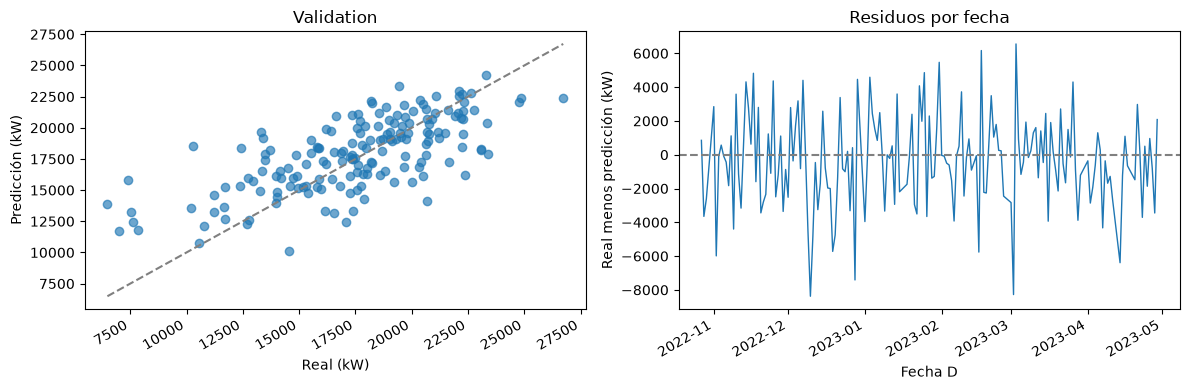

,filas,sesgo,mae
mes,,,
2022-10,3,-1802.67,2370.13
2022-11,30,-186.83,2236.10
2022-12,29,-1125.05,2729.40
2023-01,29,385.35,2279.96
2023-02,26,-184.98,1622.68
2023-03,29,-104.03,1964.94
2023-04,25,-1050.99,1800.97


In [6]:
checksums = leer_json(raiz / "data" / "checksums.json") 
val = leer_csv_verificado("validation.csv", checksums)  
columnas = mejor["columnas"]  
prediccion = diagnostico.predict(val[columnas])  
residuo = val["y"] - prediccion  
print(f"Residuo medio en Validation: {residuo.mean():.2f} kW")  

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))  
ejes[0].scatter(val["y"], prediccion, alpha=0.65)  
minimo = min(val["y"].min(), prediccion.min())  
maximo = max(val["y"].max(), prediccion.max())  
ejes[0].plot([minimo, maximo], [minimo, maximo], linestyle="--", color="gray")  
ejes[0].set(xlabel="Real (kW)", ylabel="Predicción (kW)", title="Validation")  
ejes[1].plot(val.index, residuo, linewidth=1)  
ejes[1].axhline(0, color="gray", linestyle="--")  
ejes[1].set(xlabel="Fecha D", ylabel="Real menos predicción (kW)", title="Residuos por fecha")  
fig.autofmt_xdate()  
fig.tight_layout() 
plt.show()  

mensual = pd.DataFrame({"residuo": residuo, "error_absoluto": residuo.abs()})  
mensual["mes"] = mensual.index.to_period("M")  
tabla_mensual = mensual.groupby("mes").agg(filas=("residuo", "size"), sesgo=("residuo", "mean"),
                                           mae=("error_absoluto", "mean"))  
display(tabla_mensual.round(2))  

### Importancia de las variables

Mezclamos los valores de una columna de Validation manteniendo las demás y medimos cuánto sube el MAE. Repetimos diez veces por columna. Una subida grande indica que el modelo usa la señal de esa variable en este tramo. Las predictoras correlacionadas pueden compartir señal y el resultado se interpreta en conjunto con la comparación de ventanas.

Primero repetimos la prueba con las 12 candidatas de Fase 2 y los mismos parámetros del Ridge elegido. Así se ve cuáles tenían importancia negativa antes de quitar columnas. Después mostramos la importancia de las 10 predictoras que quedaron. Para decidir el descarte usamos el MAE de Validation al volver a ajustar el modelo.

In [7]:
# Ajustamos el mismo Ridge con las 12 candidatas para ver la lista de partida.
modelo_completo = crear_modelo(mejor["modelo"], mejor["hiperparametros"])
modelo_completo.fit(X_train[columnas_fase2], y_train)

for nombre, modelo_importancia, variables in [
    ("Fase 2 completa", modelo_completo, columnas_fase2),
    ("Modelo elegido", diagnostico, mejor["columnas"]),
]:
    # El modelo queda fijo. Solo mezclamos una columna de Validation por vez.
    importancia = permutation_importance(
        modelo_importancia, val[variables], y_val,
        scoring="neg_mean_absolute_error", n_repeats=10, random_state=SEMILLA, n_jobs=1,
    )
    tabla_importancia = pd.DataFrame({
        "variable": variables,
        "aumento_mae_kw": importancia.importances_mean,
        "desvio_kw": importancia.importances_std,
    }).sort_values("aumento_mae_kw", ascending=False)
    print(nombre)
    display(tabla_importancia.round(2))

Fase 2 completa
Modelo elegido


,variable,aumento_mae_kw,desvio_kw
8,frio_roll_mean_14,209.48,34.63
11,bodega_x_calor_estacional,125.48,31.61
2,KW Linea 3_Totalizadores Energia,73.15,19.26
5,frio_hoy_d,72.67,39.17
9,frio_diff_1,57.57,27.98
7,frio_roll_mean_7,39.98,24.88
6,frio_roll_mean_3,38.64,27.75
3,Red Paste L4_Consolidado Agua,30.36,20.36
1,KW Secador Kaeser_Totalizadores Energia,21.25,17.87
0,ET Servicios (Mj)_Consolidado GasVapor,5.73,11.94


,variable,aumento_mae_kw,desvio_kw
7,frio_roll_mean_14,163.66,46.86
4,frio_hoy_d,100.49,51.96
9,bodega_x_calor_estacional,64.23,30.67
2,KW Linea 3_Totalizadores Energia,50.36,16.46
8,frio_diff_1,49.81,37.77
5,frio_roll_mean_3,38.35,38.37
1,KW Secador Kaeser_Totalizadores Energia,22.32,15.77
6,frio_roll_mean_7,21.60,28.87
0,ET Servicios (Mj)_Consolidado GasVapor,13.41,8.72
3,Red Paste L4_Consolidado Agua,13.22,14.51


## 3.4 · Reentrenamiento, Test y versión

La prueba con las 12 candidatas mostró que, al mezclar `ratio_frio_servicios` o `KW Trafo 12_Totalizadores Energia`, el MAE bajaba. Probamos quitar las dos juntas. Con ese cambio el MAE de Validation bajó de **2.149,43 a 2.126,68 kW** y elegimos la lista de **10 predictoras**, que conserva las tres medias móviles.

En esta celda volvemos a ajustar el Ridge y su escala con las 969 filas de Train + Validation, usando la lista que salió de la comparación. Después comprobamos que reproduce el ajuste del modelo guardado. Mostramos el resultado de Test que ya generó el comando de cierre.

In [8]:
from numpy.testing import assert_allclose
from src.predict import load_model

# Recuperamos las columnas de la selección y hacemos el ajuste final con ellas.
seleccion_final = leer_json(raiz / "results" / "seleccion_modelado.json")
assert seleccion_final == mejor
columnas_finales = seleccion_final["columnas"]
train_val = pd.concat([train, val])
X_final = train_val[columnas_finales]
y_final = train_val["y"]
modelo_final = crear_modelo(seleccion_final["modelo"], seleccion_final["hiperparametros"])
modelo_final.fit(X_final, y_final)

retiradas = [columna for columna in columnas_fase2 if columna not in columnas_finales]
print(f"Reentrenamiento: {len(train_val)} filas y {len(columnas_finales)} predictoras.")
print("Columnas retiradas:", ", ".join(retiradas))
display(pd.DataFrame({"Predictoras del modelo final": columnas_finales}))

# Contrastamos el ajuste con el artefacto guardado usando filas de Train + Validation.
ruta_final = raiz / "results" / "evaluacion_final.json"
if ruta_final.exists():
    evaluacion = leer_json(ruta_final)
    version = evaluacion["version"]
    registro = leer_json(raiz / "models" / "model_registry.json")[version]
    guardado = load_model(version)  # Comprueba la huella del .pkl al cargarlo.
    assert evaluacion["modelo"] == registro["modelo"] == seleccion_final["modelo"]
    assert evaluacion["variante"] == seleccion_final["variante"]
    assert guardado["columnas"] == registro["columnas"] == columnas_finales
    assert registro["hiperparametros"] == seleccion_final["hiperparametros"]
    assert registro["n_train_validation"] == len(train_val)
    assert registro["metricas_test"] == evaluacion["metricas"]["Modelo final"]
    assert_allclose(modelo_final.predict(X_final), guardado["modelo"].predict(X_final))

    # Mostramos las métricas persistidas. Este bloque no abre test.csv.
    tabla_final = pd.DataFrame.from_dict(evaluacion["metricas"], orient="index")
    print("Versión:", version, "| Fechas evaluadas en Test:", evaluacion["filas_test"])
    display(tabla_final.round(2))
else:
    print("El resultado de Test aparecerá después del cierre desde el script.")

Reentrenamiento: 969 filas y 10 predictoras.
Columnas retiradas: KW Trafo 12_Totalizadores Energia, ratio_frio_servicios
Versión: v1.0.0 | Fechas evaluadas en Test: 171


,Predictoras del modelo final
0,ET Servicios (Mj)_Consolidado GasVapor
1,KW Secador Kaeser_Totalizadores Energia
2,KW Linea 3_Totalizadores Energia
3,Red Paste L4_Consolidado Agua
4,frio_hoy_d
5,frio_roll_mean_3
6,frio_roll_mean_7
7,frio_roll_mean_14
8,frio_diff_1
9,bodega_x_calor_estacional


,mae,rmse,r2
Persistencia,3367.84,4412.38,0.40
Media móvil de 7 días,3042.61,3923.80,0.52
Modelo final,2796.89,3660.12,0.59
